In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json.json to kaggle.json.json


In [ ]:
import os
import shutil

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.copy('kaggle.json.json', '/root/.kaggle/kaggle.json.json')

os.chmod('/root/.kaggle/kaggle.json.json', 600)

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets list -s titanic

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [ ]:
!kaggle datasets download -d brendan45774/test-file

Dataset URL: https://www.kaggle.com/datasets/brendan45774/test-file
License(s): CC0-1.0
100% 11.2k/11.2k [00:00<00:00, 29.6MB/s]



In [ ]:
!unzip -o test-file.zip

Archive:  test-file.zip
  inflating: tested.csv              


In [ ]:
import os

os.listdir()

['.config', 'kaggle.json.json', 'tested.csv', 'test-file.zip', 'sample_data']

In [ ]:
import glob

csv_files = glob.glob("*.csv")
print(csv_files)

['tested.csv']


In [ ]:
import pandas as pd

df = pd.read_csv(csv_files[0])

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [ ]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Shape: (418, 12)

Columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


In [ ]:
print("Columns in dataset:")
print(df.columns)

Columns in dataset:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
for col in df.columns:
    print("\n", col)
    print(df[col].unique()[:20])


 PassengerId
[892 893 894 895 896 897 898 899 900 901 902 903 904 905 906 907 908 909
 910 911]

 Survived
[0 1]

 Pclass
[3 2 1]

 Name
['Kelly, Mr. James' 'Wilkes, Mrs. James (Ellen Needs)'
 'Myles, Mr. Thomas Francis' 'Wirz, Mr. Albert'
 'Hirvonen, Mrs. Alexander (Helga E Lindqvist)'
 'Svensson, Mr. Johan Cervin' 'Connolly, Miss. Kate'
 'Caldwell, Mr. Albert Francis'
 'Abrahim, Mrs. Joseph (Sophie Halaut Easu)' 'Davies, Mr. John Samuel'
 'Ilieff, Mr. Ylio' 'Jones, Mr. Charles Cresson'
 'Snyder, Mrs. John Pillsbury (Nelle Stevenson)' 'Howard, Mr. Benjamin'
 'Chaffee, Mrs. Herbert Fuller (Carrie Constance Toogood)'
 'del Carlo, Mrs. Sebastiano (Argenia Genovesi)' 'Keane, Mr. Daniel'
 'Assaf, Mr. Gerios' 'Ilmakangas, Miss. Ida Livija'
 'Assaf Khalil, Mrs. Mariana (Miriam")"']

 Sex
['male' 'female']

 Age
[34.5 47.  62.  27.  22.  14.  30.  26.  18.  21.   nan 46.  23.  63.
 24.  35.  45.  55.   9.  48. ]

 SibSp
[0 1 2 3 4 5 8]

 Parch
[0 1 3 2 4 6 5 9]

 Ticket
['330911' '363272' '2

In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,86
SibSp,0
Parch,0
Ticket,0
Fare,1


In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing.sort_values("Missing_Percentage", ascending=False)

,Missing_Count,Missing_Percentage
Cabin,327,78.229665
Age,86,20.574163
Fare,1,0.239234
PassengerId,0,0.000000
Name,0,0.000000
Pclass,0,0.000000
Survived,0,0.000000
Sex,0,0.000000
Parch,0,0.000000
SibSp,0,0.000000


In [ ]:
df[df["Age"].isnull()].head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
10,902,0,3,"Ilieff, Mr. Ylio",male,NaN,0,0,349220,7.8958,NaN,S
22,914,1,1,"Flegenheim, Mrs. Alfred (Antoinette)",female,NaN,0,0,PC 17598,31.6833,NaN,S
29,921,0,3,"Samaan, Mr. Elias",male,NaN,2,0,2662,21.6792,NaN,C
33,925,1,3,"Johnston, Mrs. Andrew G (Elizabeth Lily"" Watson)""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
36,928,1,3,"Roth, Miss. Sarah A",female,NaN,0,0,342712,8.0500,NaN,S


In [ ]:
df[df["Embarked"].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [ ]:
df[df["Cabin"].isnull()].head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [ ]:
import numpy as np
numeric_columns = df.select_dtypes(include=np.number).columns

print(numeric_columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')


In [ ]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,418.0,1100.500000,120.810458,892.00,996.2500,1100.5000,1204.75,1309.0000
Survived,418.0,0.363636,0.481622,0.00,0.0000,0.0000,1.00,1.0000
Pclass,418.0,2.265550,0.841838,1.00,1.0000,3.0000,3.00,3.0000
Age,332.0,30.272590,14.181209,0.17,21.0000,27.0000,39.00,76.0000
SibSp,418.0,0.447368,0.896760,0.00,0.0000,0.0000,1.00,8.0000
Parch,418.0,0.392344,0.981429,0.00,0.0000,0.0000,0.00,9.0000
Fare,417.0,35.627188,55.907576,0.00,7.8958,14.4542,31.50,512.3292


In [ ]:
categorical_columns = df.select_dtypes(include="object").columns

print(categorical_columns)

Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')


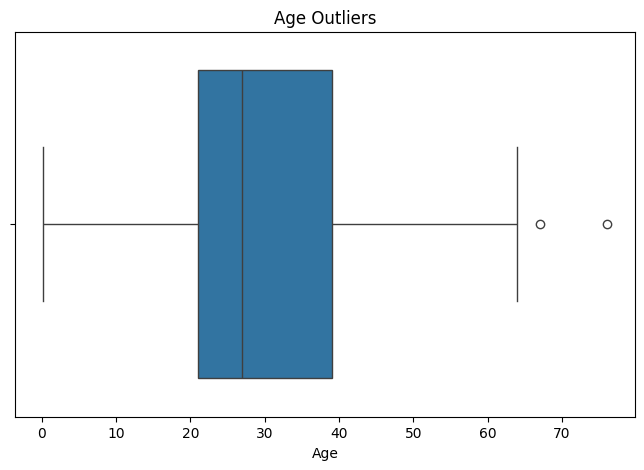

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Age")

plt.title("Age Outliers")

plt.show()

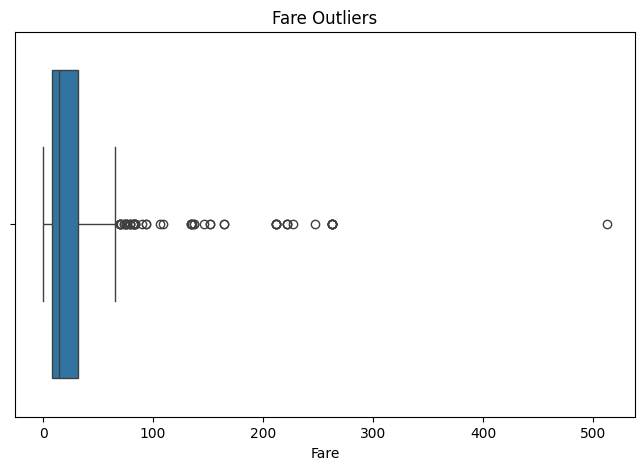

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Fare")

plt.title("Fare Outliers")

plt.show()

In [ ]:
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower:", lower_limit)
print("Upper:", upper_limit)

Q1: 7.8958
Q3: 31.5
IQR: 23.6042
Lower: -27.5105
Upper: 66.9063


In [ ]:
fare_outliers = df[
    (df["Fare"] < lower_limit) |
    (df["Fare"] > upper_limit)
]

fare_outliers

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
12,904,1,1,"Snyder, Mrs. John Pillsbury (Nelle Stevenson)",female,23.0,1,0,21228,82.2667,B45,S
24,916,1,1,"Ryerson, Mrs. Arthur Larned (Emily Maria Borie)",female,48.0,1,3,PC 17608,262.3750,B57 B59 B63 B66,C
48,940,1,1,"Bucknell, Mrs. William Robert (Emma Eliza Ward)",female,60.0,0,0,11813,76.2917,D15,C
53,945,1,1,"Fortune, Miss. Ethel Flora",female,28.0,3,2,19950,263.0000,C23 C25 C27,S
59,951,1,1,"Chaudanson, Miss. Victorine",female,36.0,0,0,PC 17608,262.3750,B61,C
64,956,0,1,"Ryerson, Master. John Borie",male,13.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C
69,961,1,1,"Fortune, Mrs. Mark (Mary McDougald)",female,60.0,1,4,19950,263.0000,C23 C25 C27,S
74,966,1,1,"Geiger, Miss. Amalie",female,35.0,0,0,113503,211.5000,C130,C
75,967,0,1,"Keeping, Mr. Edwin",male,32.5,0,0,113503,211.5000,C132,C
81,973,0,1,"Straus, Mr. Isidor",male,67.0,1,0,PC 17483,221.7792,C55 C57,S


In [ ]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [ ]:
df["Age"].isnull().sum()

np.int64(0)

In [ ]:
df[df["Embarked"].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [ ]:
df["Embarked"].mode()[0]

'S'

In [ ]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [ ]:
df["Embarked"].isnull().sum()

np.int64(0)

In [ ]:
original_df = pd.read_csv("/content/tested.csv")

original_df["CabinKnown"] = original_df["Cabin"].notna().astype(int)

df = original_df.copy()

In [ ]:
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'CabinKnown']


In [ ]:
df.drop("Cabin", axis=1, inplace=True)

In [ ]:
df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")

In [ ]:
df["Title"].value_counts()

,count
Title,
Mr,240
Miss,78
Mrs,72
Master,21
Col,2
Rev,2
Ms,1
Dr,1
Dona,1


In [ ]:
common_titles = [
    "Mr", "Miss", "Mrs", "Master"
]

df["Title"] = df["Title"].where(
    df["Title"].isin(common_titles),
    "Rare"
)

In [ ]:
df["Title"].value_counts()

,count
Title,
Mr,240
Miss,78
Mrs,72
Master,21
Rare,7


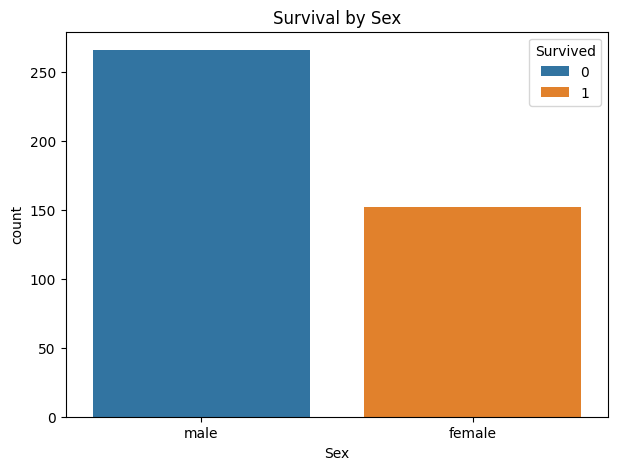

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Sex",
    hue="Survived"
)

plt.title("Survival by Sex")

plt.show()

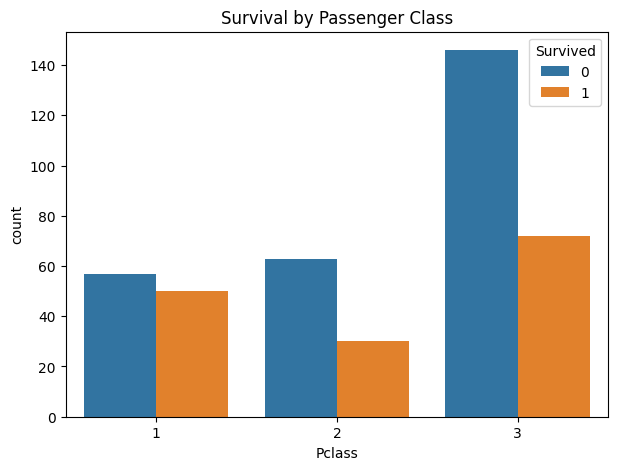

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Pclass",
    hue="Survived"
)

plt.title("Survival by Passenger Class")

plt.show()

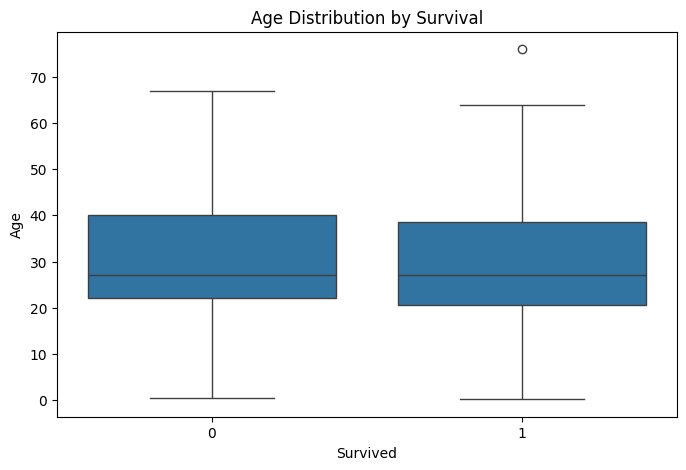

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Survived",
    y="Age"
)

plt.title("Age Distribution by Survival")

plt.show()

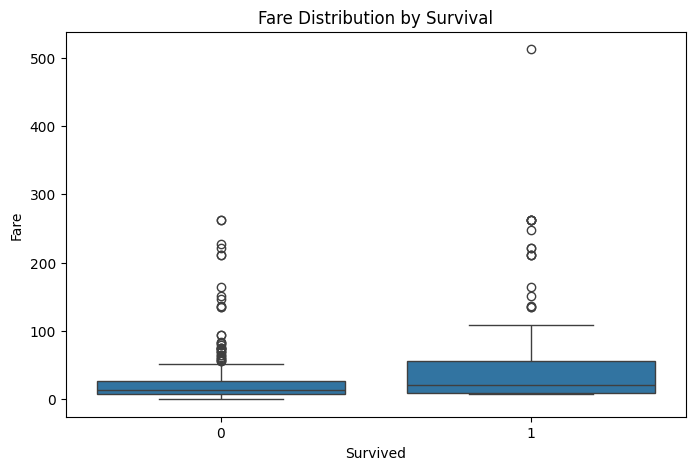

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Survived",
    y="Fare"
)

plt.title("Fare Distribution by Survival")

plt.show()

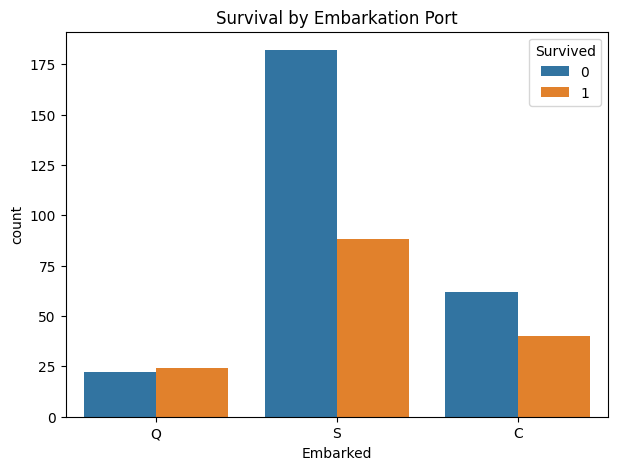

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Embarked",
    hue="Survived"
)

plt.title("Survival by Embarkation Port")

plt.show()

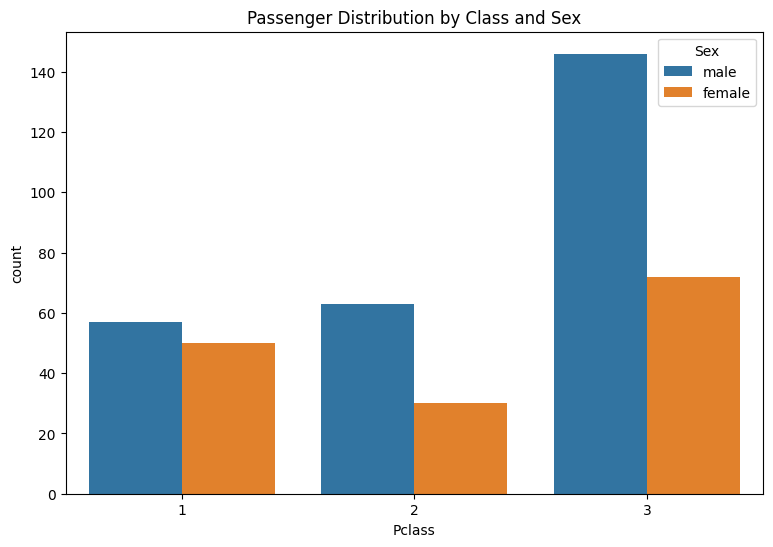

In [ ]:
plt.figure(figsize=(9,6))

sns.countplot(
    data=df,
    x="Pclass",
    hue="Sex"
)

plt.title("Passenger Distribution by Class and Sex")

plt.show()

In [ ]:
survival_table = pd.pivot_table(
    df,
    values="Survived",
    index="Pclass",
    columns="Sex",
    aggfunc="mean"
)

survival_table

Sex,female,male
Pclass,,
1,1.0,0.0
2,1.0,0.0
3,1.0,0.0


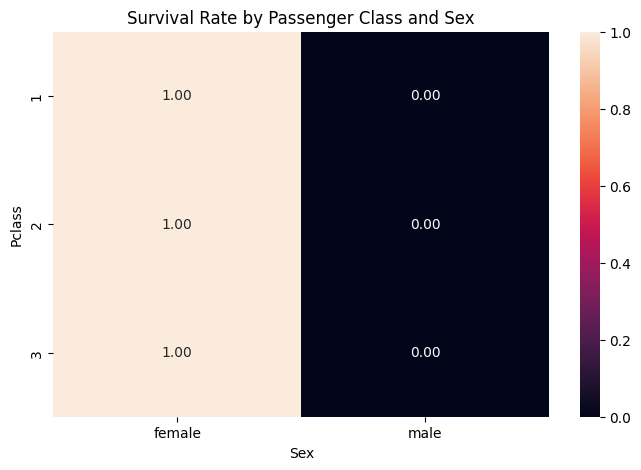

In [ ]:
plt.figure(figsize=(8,5))

sns.heatmap(
    survival_table,
    annot=True,
    fmt=".2f"
)

plt.title("Survival Rate by Passenger Class and Sex")

plt.show()

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

In [ ]:
correlation = numeric_df.corr()

correlation

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,CabinKnown
PassengerId,1.000000,-0.023245,-0.026751,-0.034102,0.003818,0.043080,0.008211,0.006462
Survived,-0.023245,1.000000,-0.108615,-0.000013,0.099943,0.159120,0.191514,0.131464
Pclass,-0.026751,-0.108615,1.000000,-0.492143,0.001087,0.018721,-0.577147,-0.690579
Age,-0.034102,-0.000013,-0.492143,1.000000,-0.091587,-0.061249,0.337932,0.377686
SibSp,0.003818,0.099943,0.001087,-0.091587,1.000000,0.306895,0.171539,0.073067
Parch,0.043080,0.159120,0.018721,-0.061249,0.306895,1.000000,0.230046,0.037237
Fare,0.008211,0.191514,-0.577147,0.337932,0.171539,0.230046,1.000000,0.560843
CabinKnown,0.006462,0.131464,-0.690579,0.377686,0.073067,0.037237,0.560843,1.000000


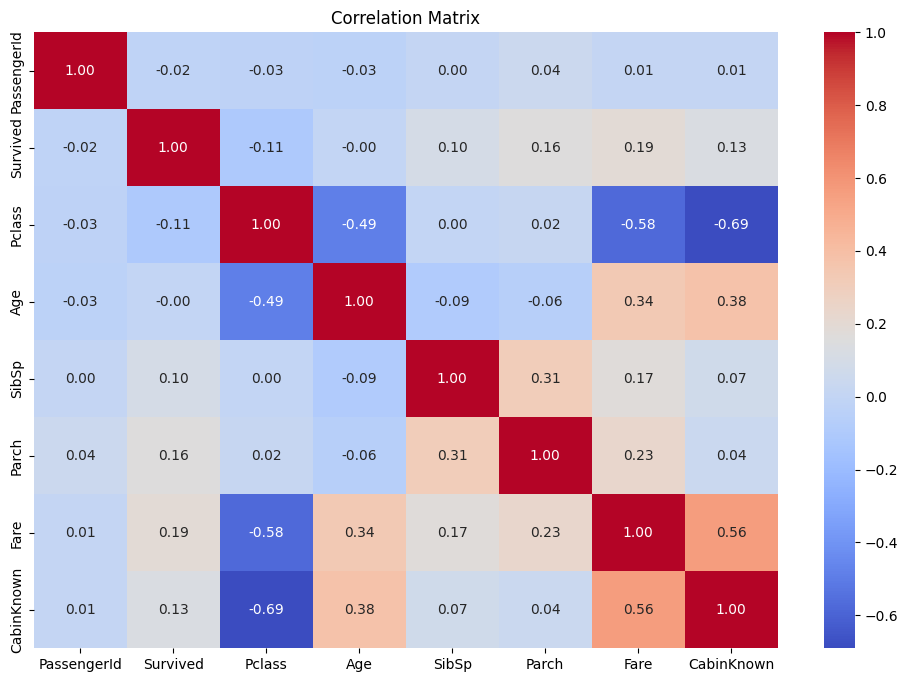

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()